# Blood–brain barrier penetration (BBBP): binary classification

Exercise from the ITMO course *Artificial Intelligence in a Chemist's Work*.

**Data:** BBBP set from MoleculeNet (1957 molecules; class 1 = penetrates, 76 %) with 41 precomputed RDKit descriptors (course file `bbbp_data.csv`).
**Task:** compare a bagging ensemble (random forest) and a boosting ensemble (gradient boosting) with the kNN models from the class,
tune them with stratified 5-fold CV, and pay attention to the minority class.


In [13]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve

In [14]:
# Data file from the course; place it in data/ before running
bb_data = pd.read_csv('data/bbbp_data.csv')

In [16]:
print('Table shape:', bb_data.shape)
bb_data.head(3)

Table shape: (1957, 44)


,name,p_np,smiles,MaxAbsEStateIndex,MinAbsEStateIndex,MaxAbsPartialCharge,FpDensityMorgan1,BCUT2D_MWLOW,PEOE_VSA12,PEOE_VSA4,...,fr_nitroso,fr_oxazole,fr_phos_acid,fr_quatN,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiophene,fr_unbrch_alkane
0,Terbutylchlorambucil,1,CC(C)(C)OC(=O)CCCc1ccc(N(CCCl)CCCl)cc1,11.682268,0.134704,0.459948,1.086957,10.074097,0.00000,0.0,...,0,0,0,0,0,0,0,0,0,0
1,40730,1,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,14.983653,0.043359,0.486917,1.307692,10.052548,5.42879,0.0,...,0,0,0,0,0,0,0,0,0,0
2,24,1,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1,10.754123,0.012527,0.493519,1.285714,10.100599,5.90718,0.0,...,0,0,0,0,0,0,0,0,0,2


In [17]:
# Class balance
print(bb_data['p_np'].value_counts())
print('Share of class 1: %.1f%%' % (100 * bb_data['p_np'].mean()))

p_np
1    1495
0     462
Name: count, dtype: int64
Share of class 1: 76.4%


In [19]:
X = bb_data.iloc[:, 3:]   # descriptor columns
y = bb_data['p_np']

print('Number of features:', X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print('Train set:', X_train.shape, ' Test set:', X_test.shape)

Number of features: 41
Train set: (1565, 41)  Test set: (392, 41)


In [20]:
# Helper: fit a model, compute test metrics and store them in a shared dict
results = {}

def evaluate(name, model, fit=True):
    if fit:
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'f1':       f1_score(y_test, y_pred),
        'f1_0':     f1_score(y_test, y_pred, pos_label=0),
        'auc':      roc_auc_score(y_test, y_proba),
        'y_proba':  y_proba,
    }
    r = results[name]
    print(f"{name}:\nAccuracy: {r['accuracy']:.3f}\nF1 (class 1): {r['f1']:.3f}\n"
          f"F1 (class 0): {r['f1_0']:.3f}\nAUC-ROC: {r['auc']:.3f}\n")
    return model

In [21]:
rf = evaluate('Random Forest', RandomForestClassifier(random_state=42))          # bagging
gb = evaluate('Gradient Boosting', GradientBoostingClassifier(random_state=42))  # boosting

Random Forest:
Accuracy: 0.870
F1 (class 1): 0.918
F1 (class 0): 0.687
AUC-ROC: 0.892

Gradient Boosting:
Accuracy: 0.852
F1 (class 1): 0.906
F1 (class 0): 0.646
AUC-ROC: 0.867



In [22]:
# Hyperparameter search, scored by ROC-AUC
param_grid = {
    'n_estimators':     [200, 500],
    'max_depth':        [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
    'max_features':     ['sqrt', 0.3],
    'class_weight':     [None, 'balanced'],
}

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

grid_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                           param_grid, cv=skfold, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC: %.4f" % grid_search.best_score_)

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV ROC-AUC: 0.8957


In [23]:
evaluate('Random Forest (tuned)', grid_search.best_estimator_, fit=False)

Random Forest (tuned):
Accuracy: 0.865
F1 (class 1): 0.915
F1 (class 0): 0.667
AUC-ROC: 0.892



RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [24]:
param_grid_gb = {
    'n_estimators':     [200, 500],
    'learning_rate':    [0.05, 0.1],
    'max_depth':        [3, 5],
    'min_samples_leaf': [1, 5],
    'max_features':     ['sqrt', None],
}

grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=42),
                       param_grid_gb, cv=skfold, scoring='roc_auc', n_jobs=-1)
grid_gb.fit(X_train, y_train)

print("Best parameters:", grid_gb.best_params_)
print("Best CV ROC-AUC: %.4f" % grid_gb.best_score_)

Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
Best CV ROC-AUC: 0.8879


In [25]:
evaluate('Gradient Boosting (tuned)', grid_gb.best_estimator_, fit=False)

Gradient Boosting (tuned):
Accuracy: 0.862
F1 (class 1): 0.912
F1 (class 0): 0.679
AUC-ROC: 0.885



GradientBoostingClassifier(learning_rate=0.05, max_depth=5, max_features='sqrt',
                           n_estimators=500, random_state=42)

In [26]:
# kNN results from the class, for comparison
results['kNN, k=5 (class)'] = {'f1': 0.888, 'f1_0': 0.618, 'auc': 0.846, 'y_proba': None}
results['kNN + Hyperopt (class)'] = {'f1': 0.916, 'f1_0': 0.709, 'auc': 0.883, 'y_proba': None}

comparison = pd.DataFrame([
    {'Model': k,
     'F1 class 1': v.get('f1', np.nan),
     'F1 class 0': v.get('f1_0', np.nan),
     'ROC-AUC':    v.get('auc', np.nan)}
    for k, v in results.items()
]).sort_values('ROC-AUC', ascending=False)

print('Models in table:', len(comparison))
comparison

Models in table: 6


,Model,F1 class 1,F1 class 0,ROC-AUC
0,Random Forest,0.917874,0.687117,0.892275
2,Random Forest (tuned),0.915200,0.666667,0.891836
3,Gradient Boosting (tuned),0.912338,0.678571,0.885108
5,kNN + Hyperopt (class),0.916000,0.709000,0.883000
1,Gradient Boosting,0.906452,0.646341,0.867224
4,"kNN, k=5 (class)",0.888000,0.618000,0.846000


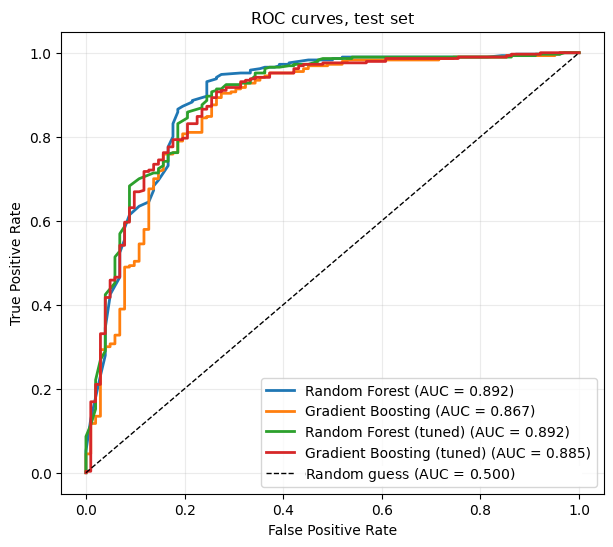

In [27]:
plt.figure(figsize=(7, 6))

for name, r in results.items():
    if r.get('y_proba') is None:      # skip models without stored probabilities
        continue
    fpr, tpr, _ = roc_curve(y_test, r['y_proba'])
    plt.plot(fpr, tpr, lw=2, label='%s (AUC = %0.3f)' % (name, r['auc']))

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves, test set')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.show()

## Conclusions

1. Two ensemble classifiers based on different principles were built: random forest (bagging, independent trees) and
   gradient boosting (sequential trees). The best result came from the random forest: AUC 0.892 vs. 0.883 for the tuned kNN from the class.
2. Tuning helped the two models differently. For boosting it gave a clear gain (ROC-AUC 0.867 → 0.885). For the random forest the test score
   did not improve, although the cross-validation score rose to 0.896.
3. The weak point of all models is the minority class (non-penetrating molecules): F1 for class 0 is 0.65–0.69, while the tuned kNN reached 0.71.
   The reason is the 76/24 class imbalance: predicting the majority class more often pays off for the models. Improvements should come from
   choosing the classification threshold according to the cost of errors, or from a larger feature set.
